# NeuralProject - Code Hallucination Detection (Google Colab, T4 GPU)

Detect whether an LLM-generated code completion is **correct (0)** or **hallucinated (1)** using the Delulu dataset.

**Before you start:** `Runtime -> Change runtime type -> T4 GPU`.

Run the cells **from top to bottom**. Every step saves its results to `outputs/`. If the session
disconnects, re-run cells 1-4 and continue - finished steps are detected and **skipped**
(add `--force` to a command to retrain on purpose).

Each training step runs as a separate `!python -m ...` process, so GPU memory is fully released
after every step and only one model is in GPU memory at a time.

## 1. Mount Google Drive (skip if you uploaded the folder directly to `/content`)

In [1]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running on Colab - skipping Drive mount.')

Mounted at /content/drive


## 2. Set the project root
Edit `PROJECT_ROOT` if your folder is somewhere else. If it is `None`, the cell searches Drive for it.

In [2]:
import os, sys
from pathlib import Path

PROJECT_ROOT = None  # e.g. '/content/drive/MyDrive/NeuralProject'

if PROJECT_ROOT is None:
    candidates = [Path('/content/drive/MyDrive/NeuralProject'), Path('/content/NeuralProject')]
    drive_root = Path('/content/drive/MyDrive')
    if drive_root.exists():
        candidates += sorted(drive_root.glob('*/NeuralProject')) + sorted(drive_root.glob('*/*/NeuralProject'))
    found = [p for p in candidates if (p / 'src').is_dir() and (p / 'data').is_dir()]
    if not found:
        raise FileNotFoundError('Could not find the NeuralProject folder. Upload it to Drive '
                                '(MyDrive/NeuralProject) or set PROJECT_ROOT manually.')
    PROJECT_ROOT = str(found[0])

os.chdir(PROJECT_ROOT)                       # `!python -m src....` commands run from here
os.environ['NEURALPROJECT_ROOT'] = PROJECT_ROOT
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
print('Project root:', os.getcwd())
print(sorted(os.listdir('.')))

Project root: /content/drive/MyDrive/NeuralProject
['.gitignore', 'INSTRUCTIONS.md', 'README.md', 'data', 'notebooks', 'outputs', 'requirements.txt', 'src', 'tests']


## 3. Install dependencies
Colab already ships a CUDA build of PyTorch - **keep it**. `requirements.txt` only asks for `torch>=2.3`,
so pip leaves Colab's PyTorch untouched and only installs/updates the other packages.

In [3]:
!pip install -q -r requirements.txt

## 4. Verify the GPU

In [4]:
import torch
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print('GPU:', props.name, f'| memory: {props.total_memory / 1e9:.1f} GB')
else:
    print('WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU, then re-run from cell 1.')

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4 | memory: 15.6 GB


In [5]:
!nvidia-smi

Sun Nov  1 10:59:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 5. Load the dataset (quick look)

In [6]:
import pandas as pd
df = pd.read_csv('data/delulu.csv')
print(df.shape)
print(df['hallucination_type'].value_counts())
df.head(3)

(1947, 13)
hallucination_type
undefinedvariable    576
import               476
method               460
parameter            435
Name: count, dtype: int64


,benchmark_id,image_tag,language,file_path,hallucination_type,prompt,suffix,golden_completion,hallucinated_completion,error_message,metadata,license,repo_url
0,go-method-e9ac561d7779,delulu-go-method-e9ac561d7779:v1,go,api/gen/v1/query.pb.go,method,// Code generated by protoc-gen-go. DO NOT EDI...,\n\t\t}\n\t\treturn ms\n\t}\n\treturn mi.Messa...,StoreMessageInfo(mi),CacheMessageInfo(mi),ms.CacheMessageInfo undefined (type *impl.mess...,"{""language"": ""go"", ""file_path"": ""api/gen/v1/qu...",Apache-2.0,https://github.com/Decade-qiu/Go2NetSpectra
1,python-undefinedvariable-681700c5cbff,delulu-python-undefinedvariable-681700c5cbff:v1,python,web/scrape_really_useful_boxes.py,undefinedvariable,"#!/usr/bin/env python3\n""""""\nScrape the Really...","if ""Dimensions"" in p.text)\n\n lines = dim...","find_all(""p"")","find_all(""p"", attrs={""class"": paragraph_class})",name 'paragraph_class' is not defined,"{""language"": ""python"", ""file_path"": ""web/scrap...",MIT,NaN
2,typescript-import-452f0459d667,delulu-typescript-import-452f0459d667:v1,typescript,backend/src/migration/entity-migrations/v3.7.0.ts,import,NaN,\n\nconst TRANSFORMERS_TABLE = 'transformers';...,import { Knex } from 'knex';,import { Knex } from 'knex-core';,Cannot find module 'knex-core' or its correspo...,"{""language"": ""typescript"", ""file_path"": ""backe...",EUPL-1.2,https://github.com/OptimistikSAS/OIBus


## 6. PHASE 1 - Dataset exploration

In [7]:
!python -u -m src.data_exploration

PHASE 1 - DATASET EXPLORATION
Loaded /content/drive/MyDrive/NeuralProject/data/delulu.csv: 1947 rows x 13 columns
Creating figures ...
  saved figure -> /content/drive/MyDrive/NeuralProject/outputs/figures/eda_hallucination_categories.png
  saved figure -> /content/drive/MyDrive/NeuralProject/outputs/figures/eda_languages.png
  saved figure -> /content/drive/MyDrive/NeuralProject/outputs/figures/eda_language_by_category.png
  saved figure -> /content/drive/MyDrive/NeuralProject/outputs/figures/eda_completion_lengths.png
  saved figure -> /content/drive/MyDrive/NeuralProject/outputs/figures/eda_prompt_suffix_lengths.png
  saved figure -> /content/drive/MyDrive/NeuralProject/outputs/figures/eda_missing_values.png

Summary
  rows=1947, languages=7, repos=319
  categories:
                    count  percent
hallucination_type                
undefinedvariable     576    29.58
import                476    24.45
method                460    23.63
parameter             435    22.34
  suspicio

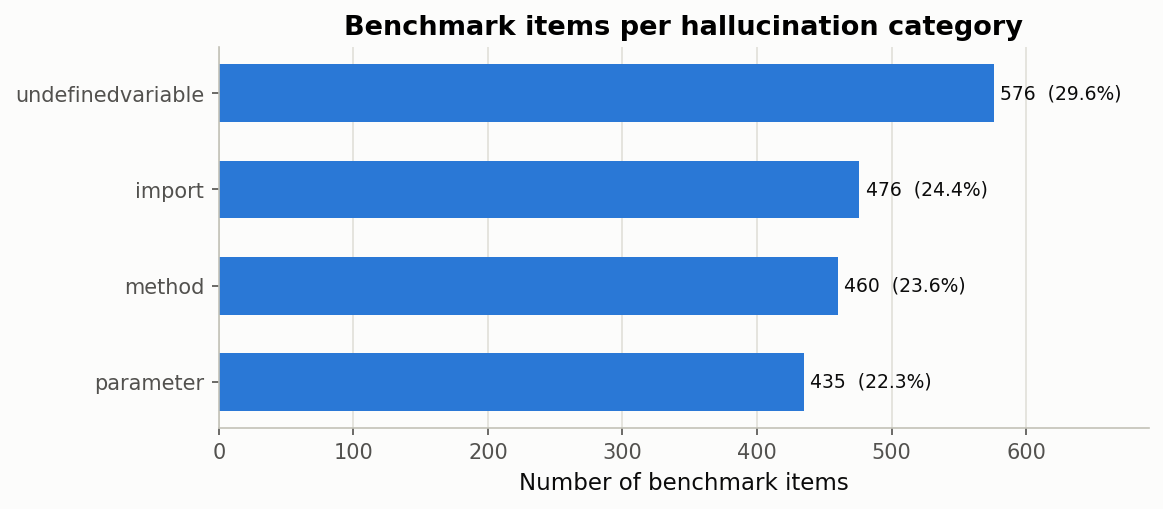

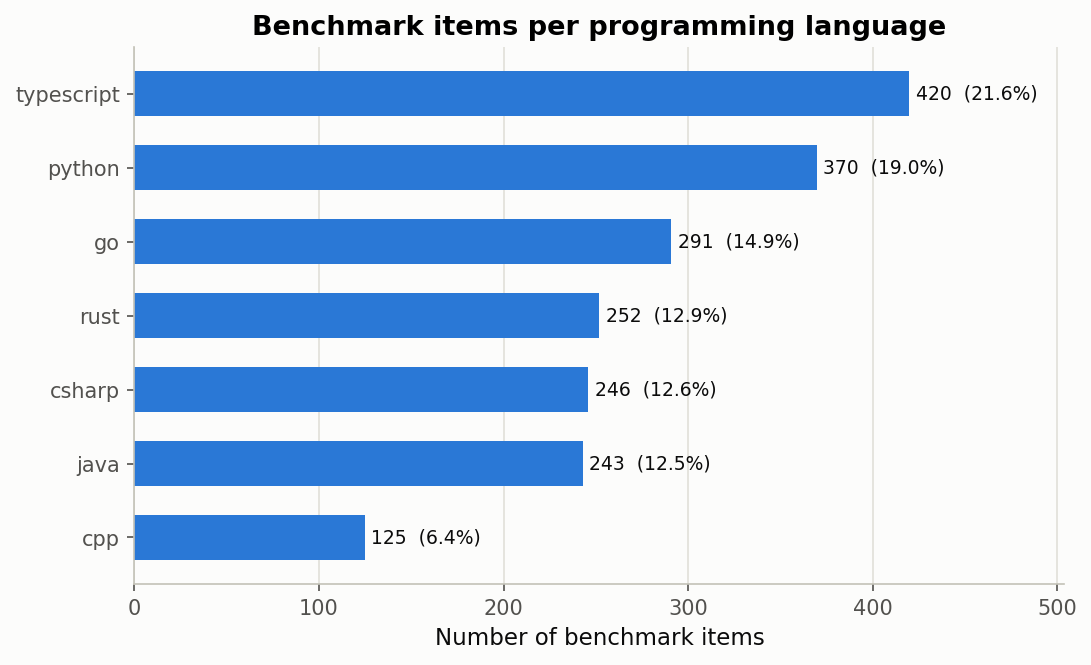

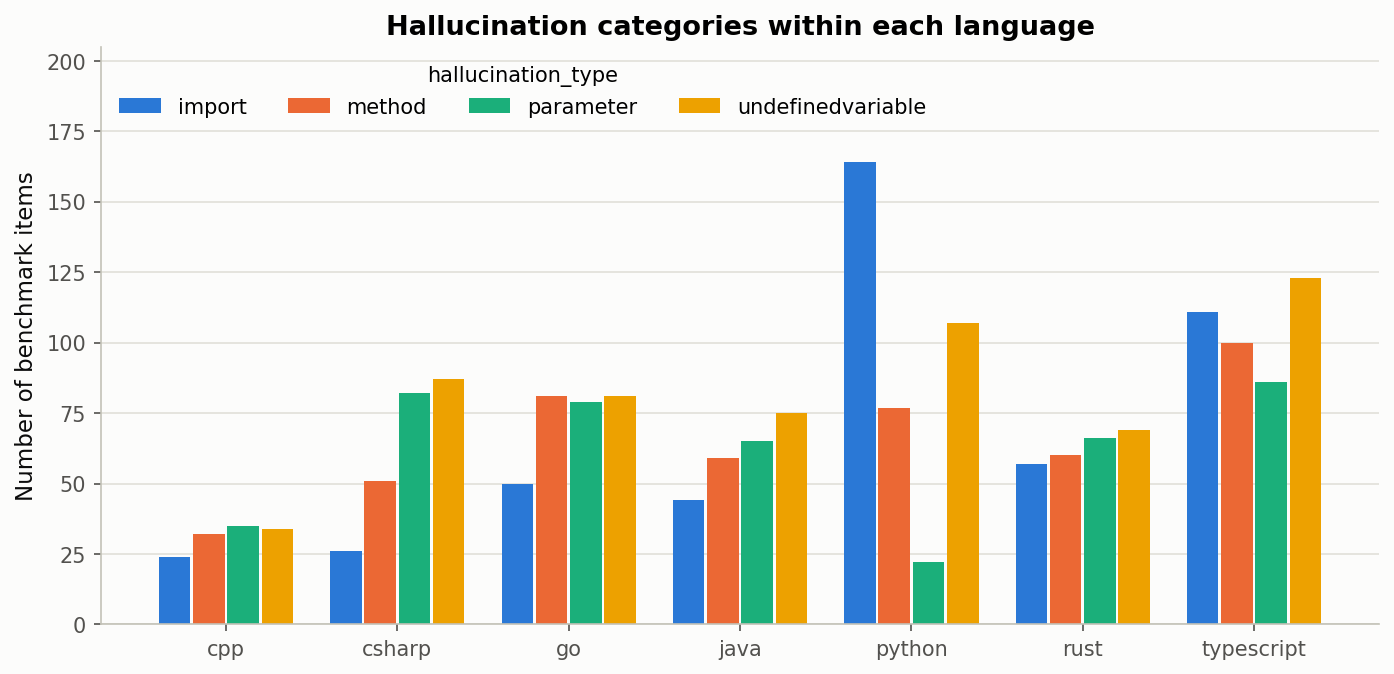

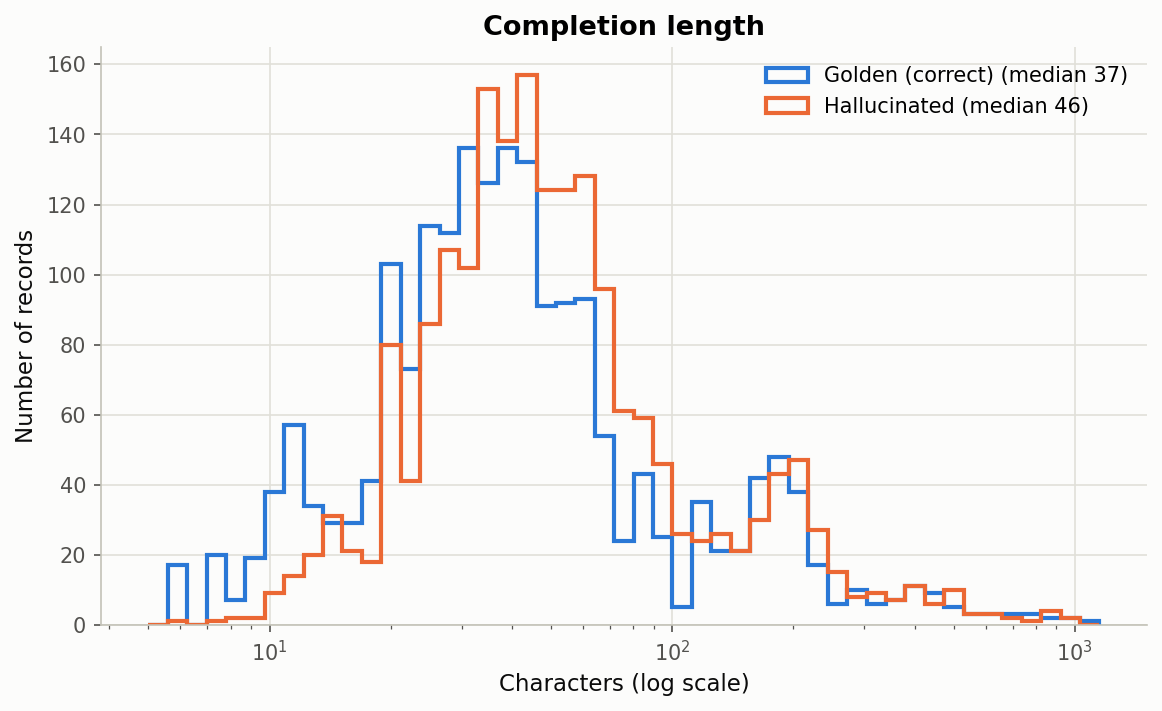

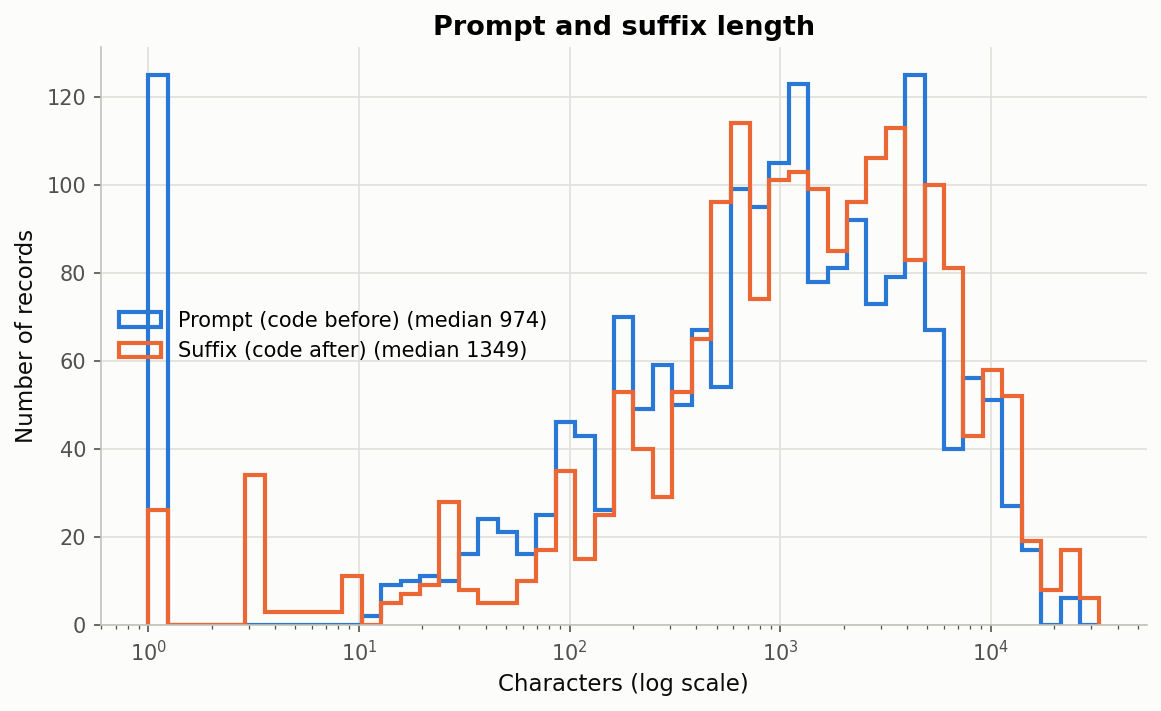

In [8]:
from IPython.display import Image, Markdown, display
for name in ['eda_hallucination_categories', 'eda_languages', 'eda_language_by_category',
             'eda_completion_lengths', 'eda_prompt_suffix_lengths']:
    display(Image(f'outputs/figures/{name}.png', width=700))

## 7. Train / validation / test split (70 / 15 / 15)
Grouped by code context so both completions of a benchmark item - and identical golden
examples shared by several items - stay in the same split.

The split files are already included in `data/processed/`, and the saved results were trained on
them, so this cell **keeps the existing split** (it only creates one if it is missing). Only use
`--force` if you really want a new split, and then retrain every model with `--force`.

In [9]:
!python -u -m src.data_split

TRAIN / VALIDATION / TEST SPLIT (grouped by context_id)
Split files already exist - keeping them (use --force to recreate).
If you recreate the split, retrain every model with --force afterwards.


## 8. PHASE 2 - TF-IDF baselines (Logistic Regression, Linear SVM) + Task B (4 categories)

In [10]:
!python -u -m src.baseline_models

11:01:44 | Task A baselines already trained - skipping (use --force to retrain).
11:01:44 | Task B baselines already trained - skipping (use --force to retrain).


## 9. PHASE 3 - GRU and LSTM

In [11]:
!python -u -m src.rnn_models

11:02:02 | ======================================================================
11:02:02 | PHASE 3 - GRU classifier
11:02:02 | ======================================================================
[device] Using GPU: Tesla T4
11:02:05 |   Vocabulary (train only): 6271 tokens | <unk> rate: train=0.01%, validation=1.89%, test=1.82%
11:02:05 |   Model: RNNClassifier(
  (embedding): Embedding(6271, 128, padding_idx=0)
  (rnn): GRU(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=512, out_features=1, bias=True)
)
  Trainable parameters: 1,001,345
11:02:16 |   epoch   1 | train loss 0.6887 | val loss 0.6723 | val acc 0.5693 | 4s  <- best, checkpoint saved
11:02:18 |   epoch   2 | train loss 0.6708 | val loss 0.6660 | val acc 0.6284 | 2s  <- best, checkpoint saved
11:02:20 |   epoch   3 | train loss 0.6601 | val loss 0.6682 | val acc 0.6081 | 3s
11:02:24 |   epoch   4 | train loss 0.6521 | val loss 0.6582 | val ac

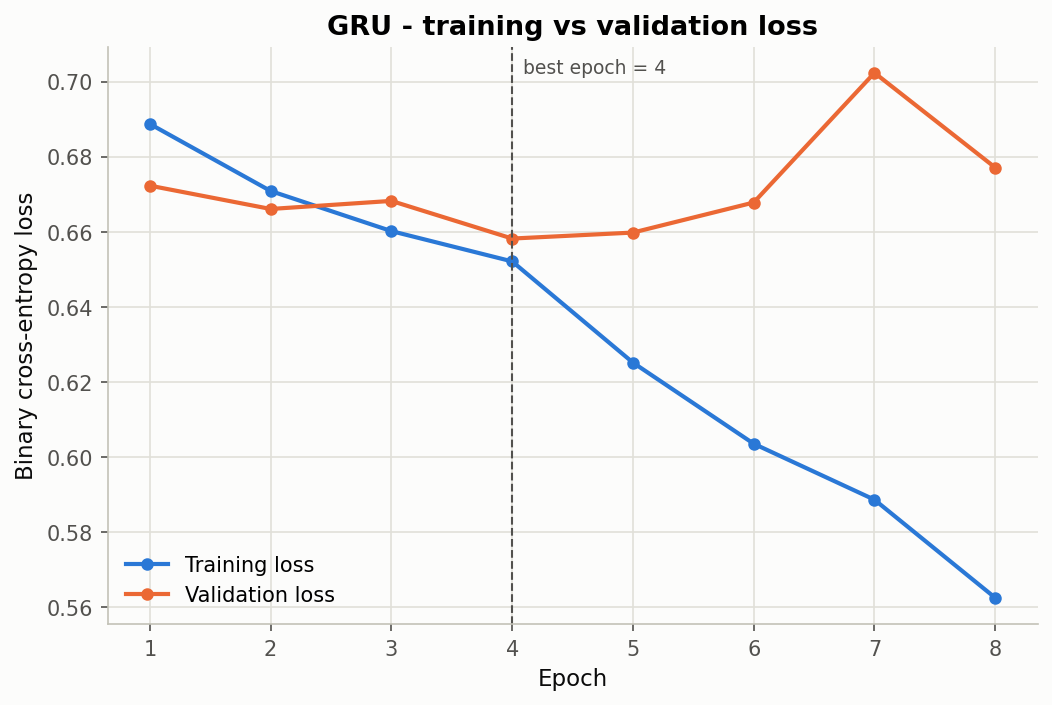

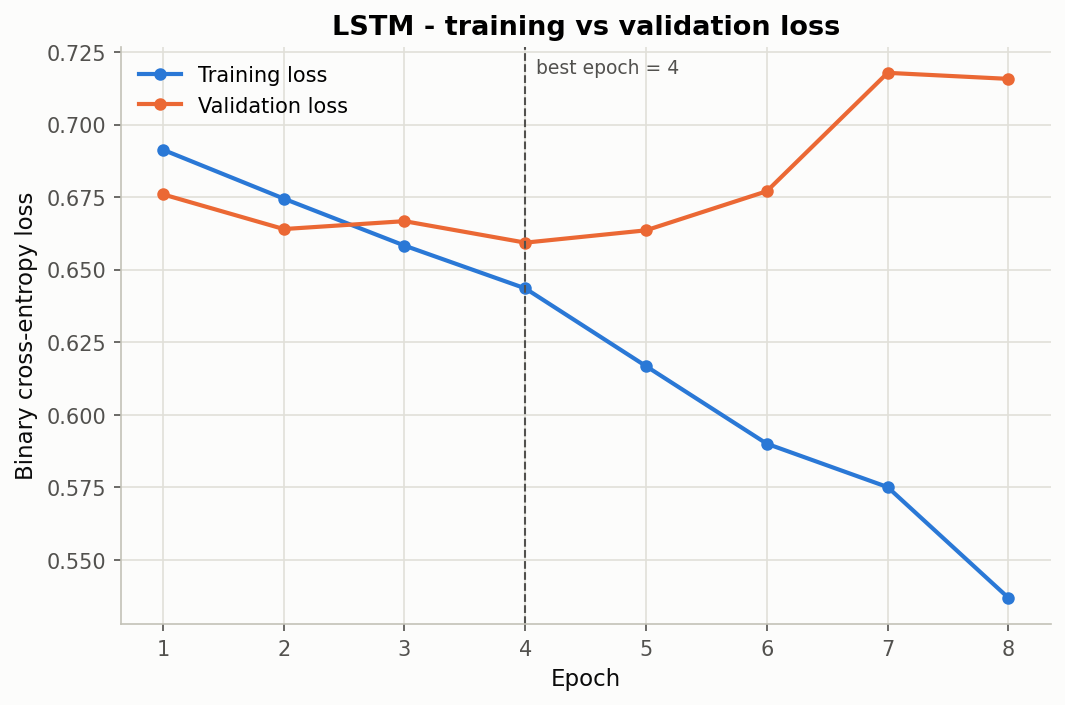

In [12]:
from IPython.display import Image, display
for name in ['loss_curve_gru', 'loss_curve_lstm']:
    display(Image(f'outputs/figures/{name}.png', width=600))

## 10. PHASE 4 - Frozen CodeBERT (feature extraction + trained head)

In [13]:
!python -u -m src.pretrained_models --model codebert

11:03:48 | ======================================================================
11:03:48 | PHASE 4 - codebert: FROZEN encoder + trainable classification head
11:03:48 | ======================================================================
[device] Using GPU: Tesla T4
config.json: 100% 498/498 [00:00<00:00, 1.98MB/s]
tokenizer_config.json: 100% 25.0/25.0 [00:00<00:00, 140kB/s]
vocab.json: 100% 899k/899k [00:00<00:00, 42.5MB/s]
merges.txt: 100% 456k/456k [00:00<00:00, 73.9MB/s]
special_tokens_map.json: 100% 150/150 [00:00<00:00, 899kB/s]

pytorch_model.bin: downloading bytes:  32% 158M/499M [00:01<00:01, 187MB/s, 13.1MB/s  ]
pytorch_model.bin: reconstructing file:  24% 118M/499M [00:01<00:04, 84.4MB/s]
pytorch_model.bin: downloading bytes:  75% 375M/499M [00:02<00:00, 304MB/s, 31.3MB/s  ]
pytorch_model.bin: downloading bytes:  85% 425M/499M [00:02<00:00, 234MB/s, 36.3MB/s  ]
pytorch_model.bin: downloading bytes:  95% 473M/499M [00:02<00:00, 233MB/s, 39.8MB/s  ]
pytorch_model.bin: down

## 11. PHASE 4 - Frozen GraphCodeBERT (used as a sequence encoder, see README)

In [14]:
!python -u -m src.pretrained_models --model graphcodebert

11:05:08 | ======================================================================
11:05:08 | PHASE 4 - graphcodebert: FROZEN encoder + trainable classification head
11:05:08 | ======================================================================
[device] Using GPU: Tesla T4
config.json: 100% 539/539 [00:00<00:00, 2.84MB/s]
tokenizer_config.json: 100% 25.0/25.0 [00:00<00:00, 36.4kB/s]
vocab.json: 100% 899k/899k [00:00<00:00, 39.7MB/s]
merges.txt: 100% 456k/456k [00:00<00:00, 105MB/s]
special_tokens_map.json: 100% 772/772 [00:00<00:00, 4.97MB/s]

pytorch_model.bin: downloading bytes:  29% 146M/499M [00:01<00:01, 192MB/s, 11.3MB/s  ]
pytorch_model.bin: reconstructing file:  13% 67.1M/499M [00:01<00:09, 43.8MB/s]
pytorch_model.bin: downloading bytes:  91% 456M/499M [00:02<00:00, 200MB/s, 37.7MB/s  ]
pytorch_model.bin: reconstructing file:  66% 331M/499M [00:04<00:02, 65.4MB/s, 15.4MB/s  ]
pytorch_model.bin: reconstructing file:  81% 404M/499M [00:05<00:01, 87.5MB/s, 26.4MB/s  ]
pytorch_mo

## 12. PHASE 5 - Fine-tune ONLY the final two CodeBERT layers
Prints the trainable/frozen parameter counts and stops if any wrong layer is unfrozen.
Takes roughly 10-25 minutes on a T4.

In [15]:
!python -u -m src.finetuning --model codebert

11:06:39 | ======================================================================
11:06:39 | PHASE 5 - codebert: fine-tune ONLY the final 2 encoder layers + head
11:06:39 | ======================================================================
[device] Using GPU: Tesla T4
Loading weights: 100% 197/197 [00:00<00:00, 25212.92it/s]
11:06:46 |   Head initialised from the Phase 4 head: /content/drive/MyDrive/NeuralProject/outputs/models/codebert_frozen/head.pt
11:06:46 |   Encoder layers: 12  |  unfrozen: the last 2 (layers 10-11)
11:06:46 |   Trainable parameters: 14,569,473
11:06:46 |   Frozen parameters   : 109,879,296
11:06:46 |   Trainable blocks    : ['backbone.encoder.layer.10', 'backbone.encoder.layer.11', 'head']
11:06:46 |   Verification passed: only the final layers + head are trainable; embeddings and earlier layers are frozen.
11:06:49 |   train     : 2710 examples, mean length 456 tokens
11:06:50 |   validation: 592 examples, mean length 472 tokens
11:06:51 |   test      : 592

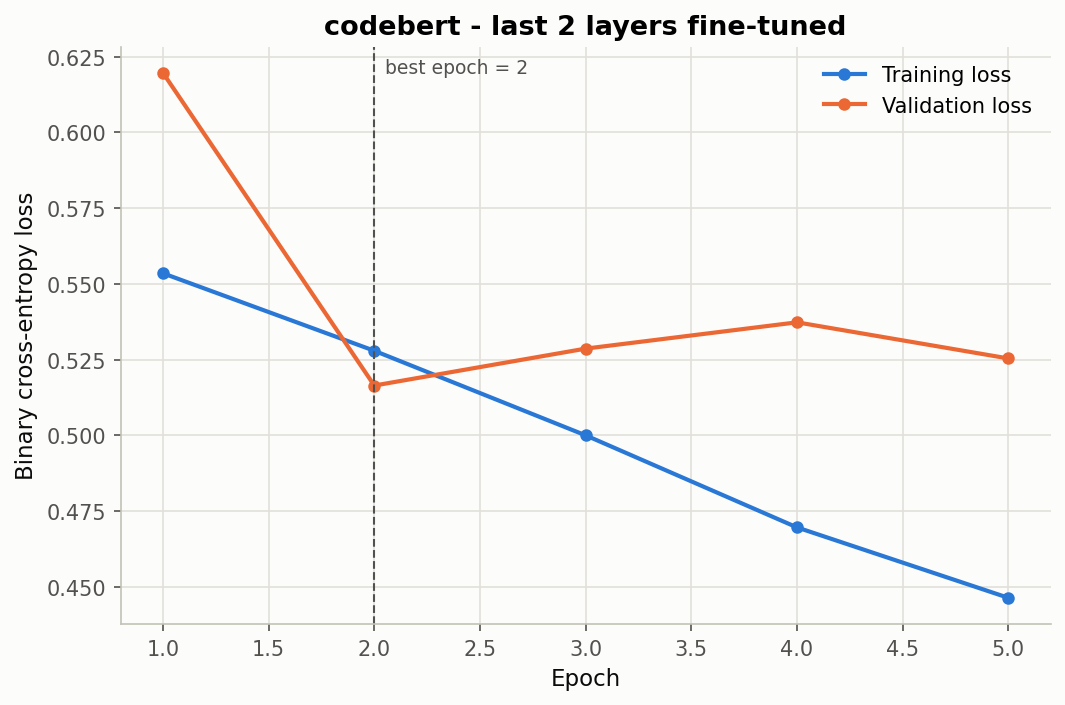

In [16]:
from IPython.display import Image, display
display(Image('outputs/figures/loss_curve_codebert_finetuned_last2.png', width=600))

### 12b. (Optional) Same final-two-layer recipe for GraphCodeBERT

In [17]:
!python -u -m src.finetuning --model graphcodebert

11:10:42 | ======================================================================
11:10:42 | PHASE 5 - graphcodebert: fine-tune ONLY the final 2 encoder layers + head
11:10:42 | ======================================================================
[device] Using GPU: Tesla T4
Loading weights: 100% 197/197 [00:00<00:00, 22195.66it/s]
11:10:49 |   Head initialised from the Phase 4 head: /content/drive/MyDrive/NeuralProject/outputs/models/graphcodebert_frozen/head.pt
11:10:49 |   Encoder layers: 12  |  unfrozen: the last 2 (layers 10-11)
11:10:49 |   Trainable parameters: 14,569,473
11:10:49 |   Frozen parameters   : 109,879,296
11:10:49 |   Trainable blocks    : ['backbone.encoder.layer.10', 'backbone.encoder.layer.11', 'head']
11:10:49 |   Verification passed: only the final layers + head are trainable; embeddings and earlier layers are frozen.
11:10:53 |   train     : 2710 examples, mean length 456 tokens
11:10:54 |   validation: 592 examples, mean length 472 tokens
11:10:54 |   test 

## 13. PHASE 6 - Evaluate and compare all models on the untouched test set

In [18]:
!python -u -m src.evaluation

PHASE 6 - COMPARING ALL MODELS ON THE TEST SET
                 display_name    status  accuracy  precision  recall     f1  roc_auc
          Logistic Regression completed    0.7213     0.6825  0.8277 0.7481   0.7981
                   Linear SVM completed    0.7196     0.6816  0.8243 0.7462   0.8007
                          GRU completed    0.6486     0.6803  0.5608 0.6148   0.6912
                         LSTM completed    0.6588     0.6958  0.5642 0.6231   0.6998
            CodeBERT (frozen) completed    0.7365     0.7201  0.7736 0.7459   0.8184
     CodeBERT (last 2 layers) completed    0.7449     0.7636  0.7095 0.7356   0.8259
       GraphCodeBERT (frozen) completed    0.7399     0.7432  0.7331 0.7381   0.8180
GraphCodeBERT (last 2 layers) completed    0.7466     0.7786  0.6892 0.7312   0.8359

Table saved -> /content/drive/MyDrive/NeuralProject/outputs/metrics/model_comparison.csv
  saved figure -> /content/drive/MyDrive/NeuralProject/outputs/figures/comparison_accuracy.png
  s

## 14. Comparison graphs

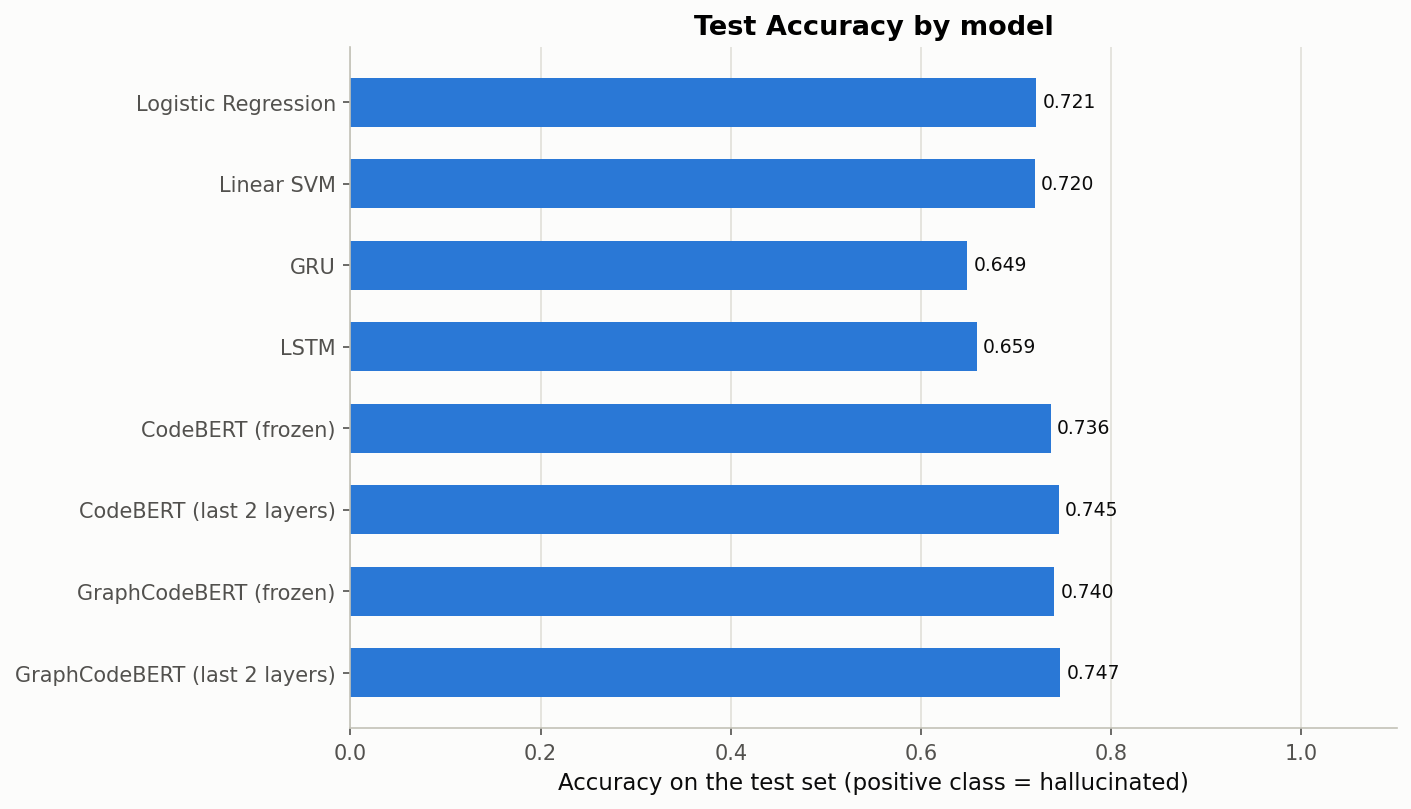

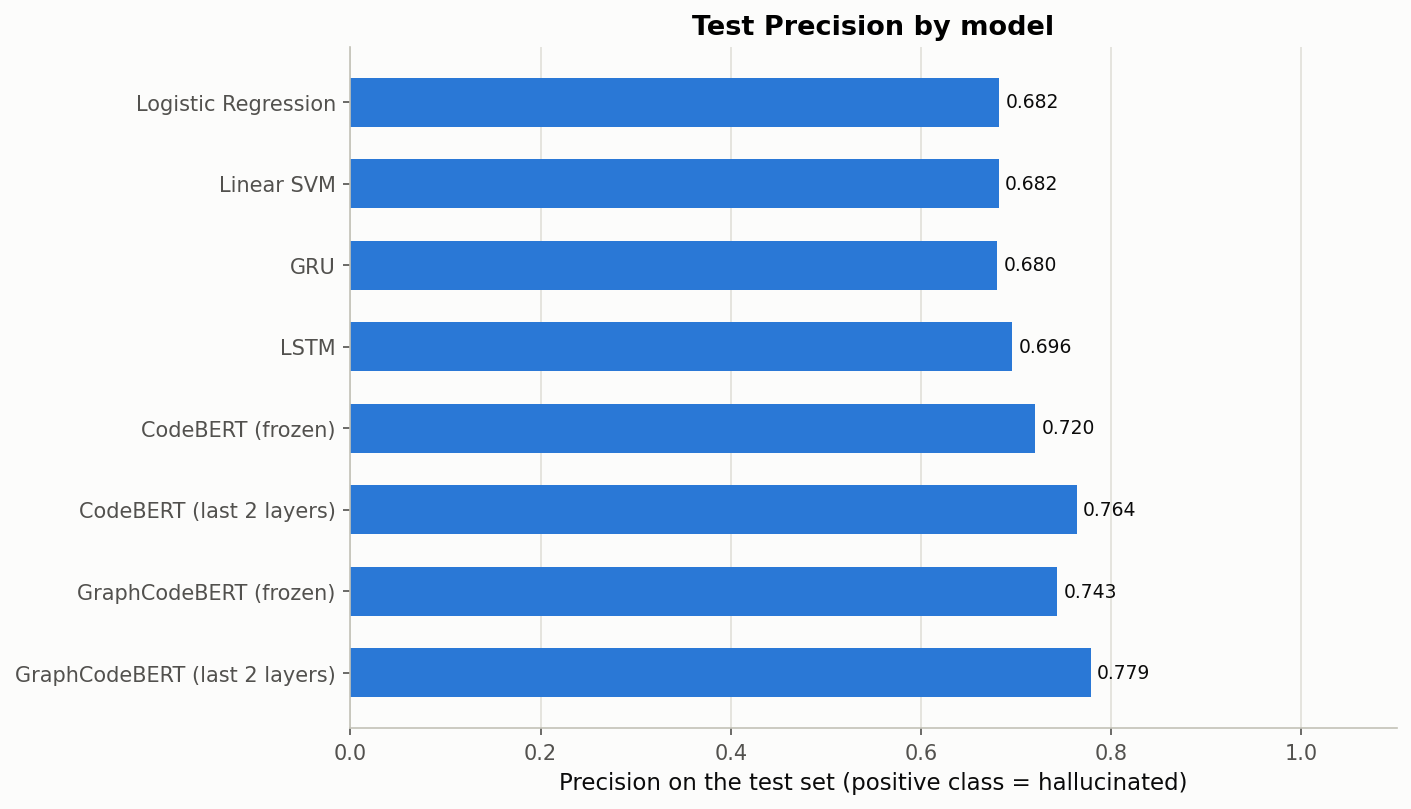

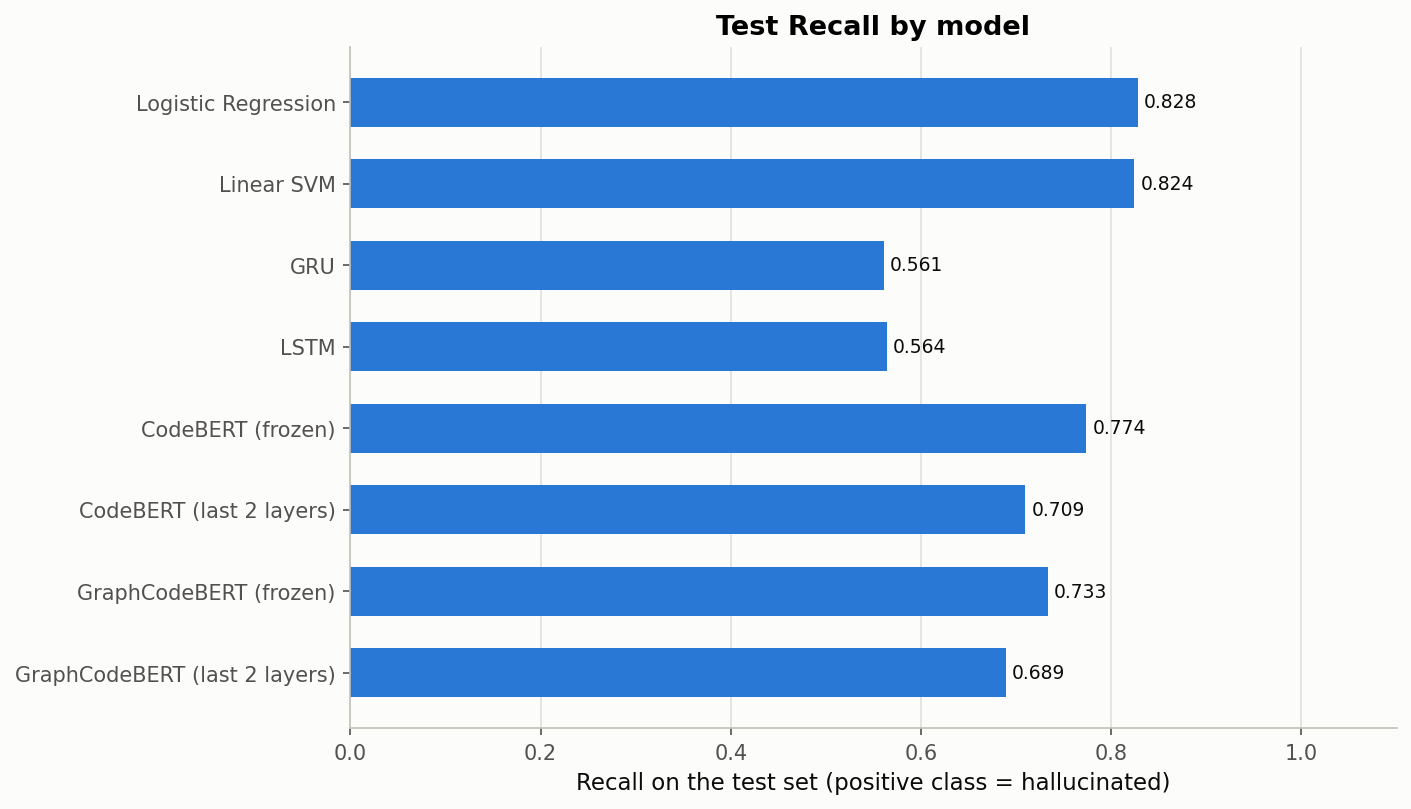

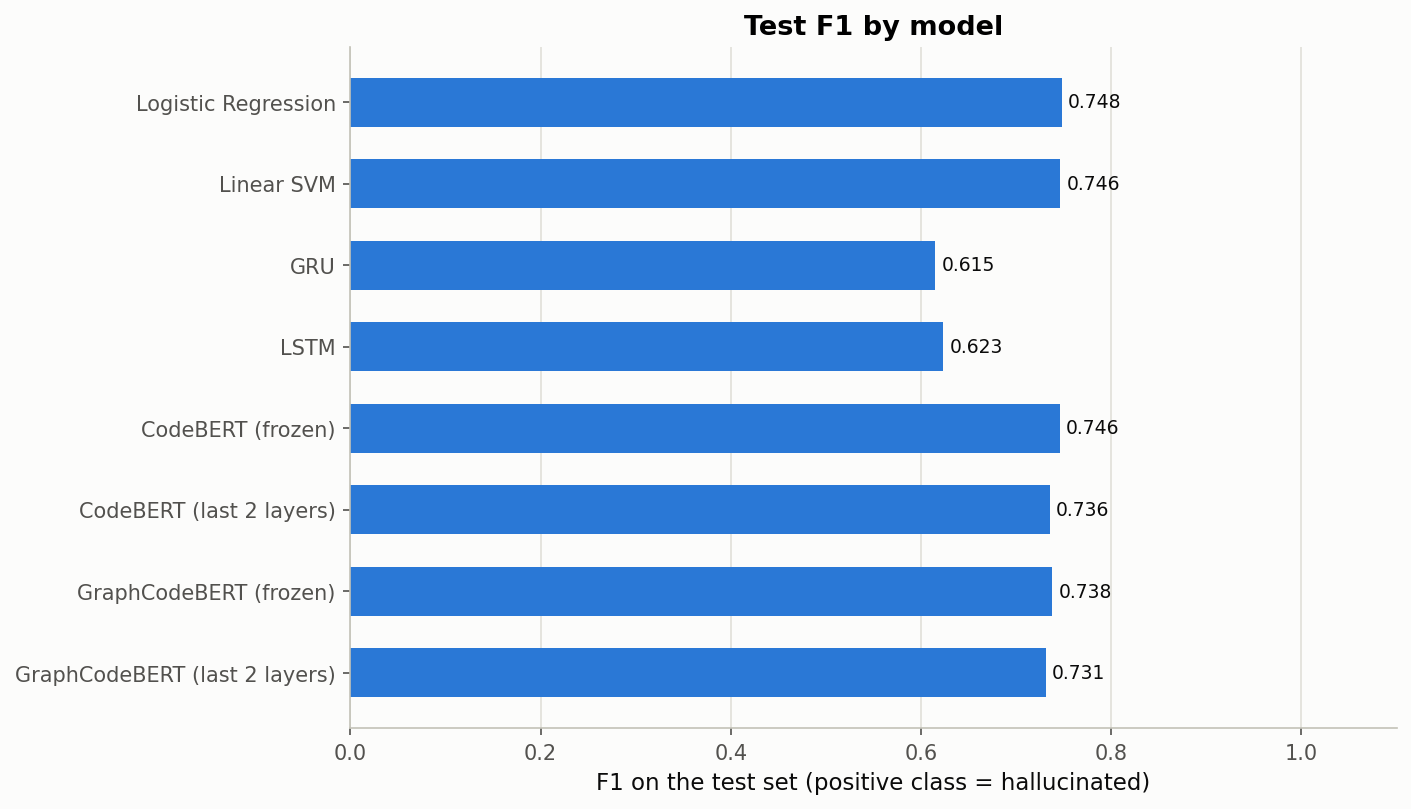

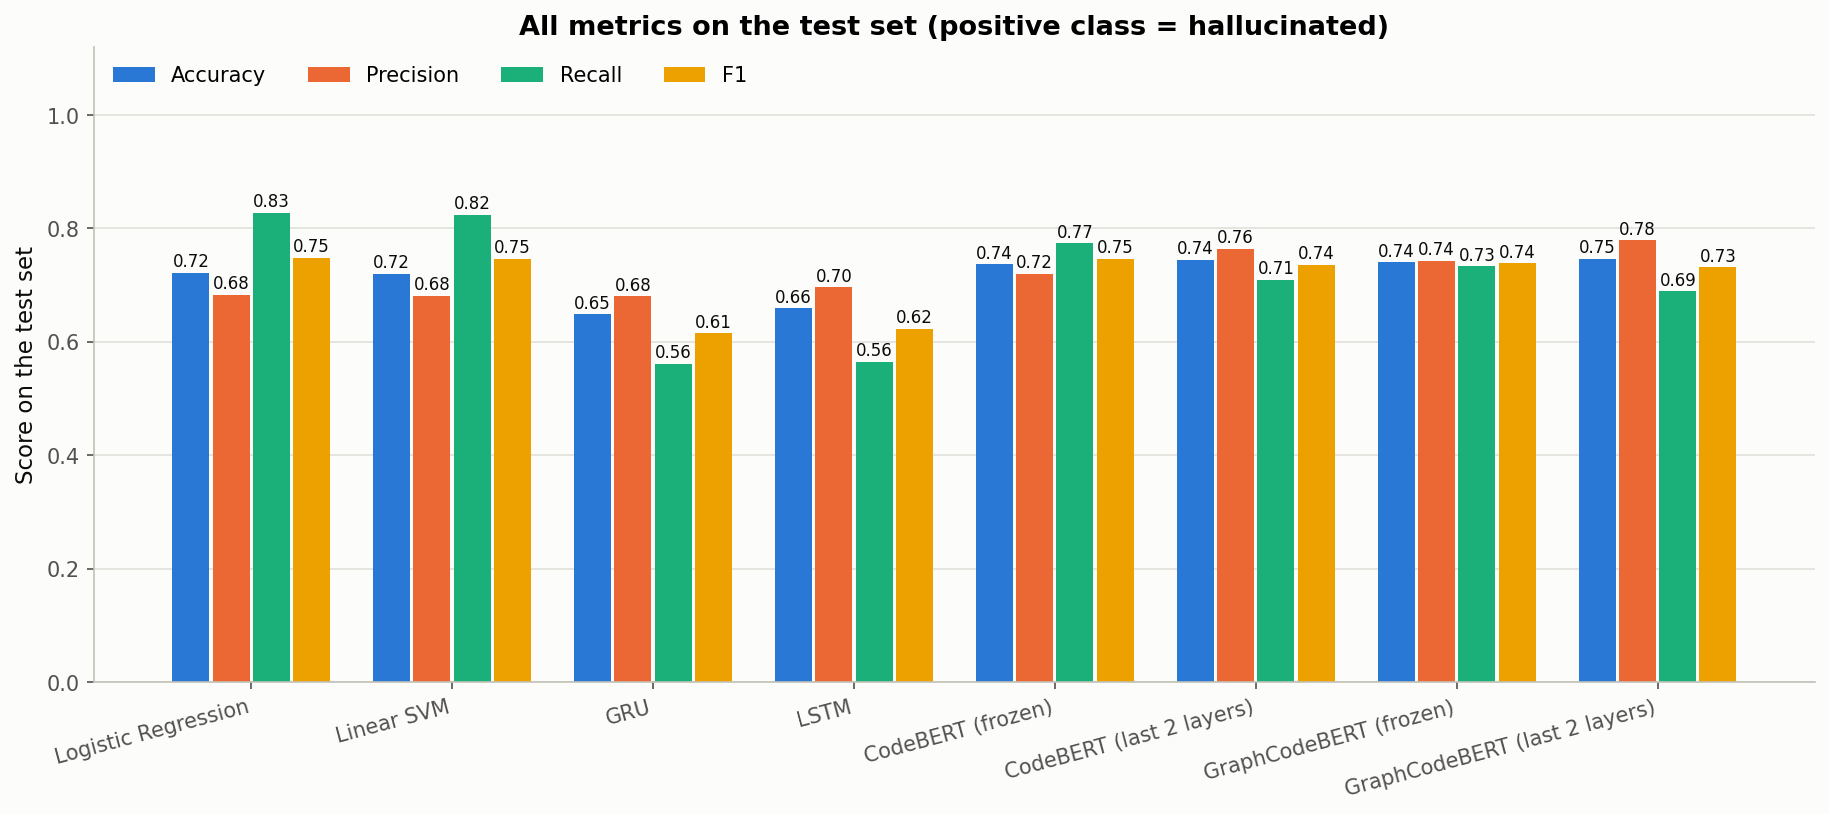

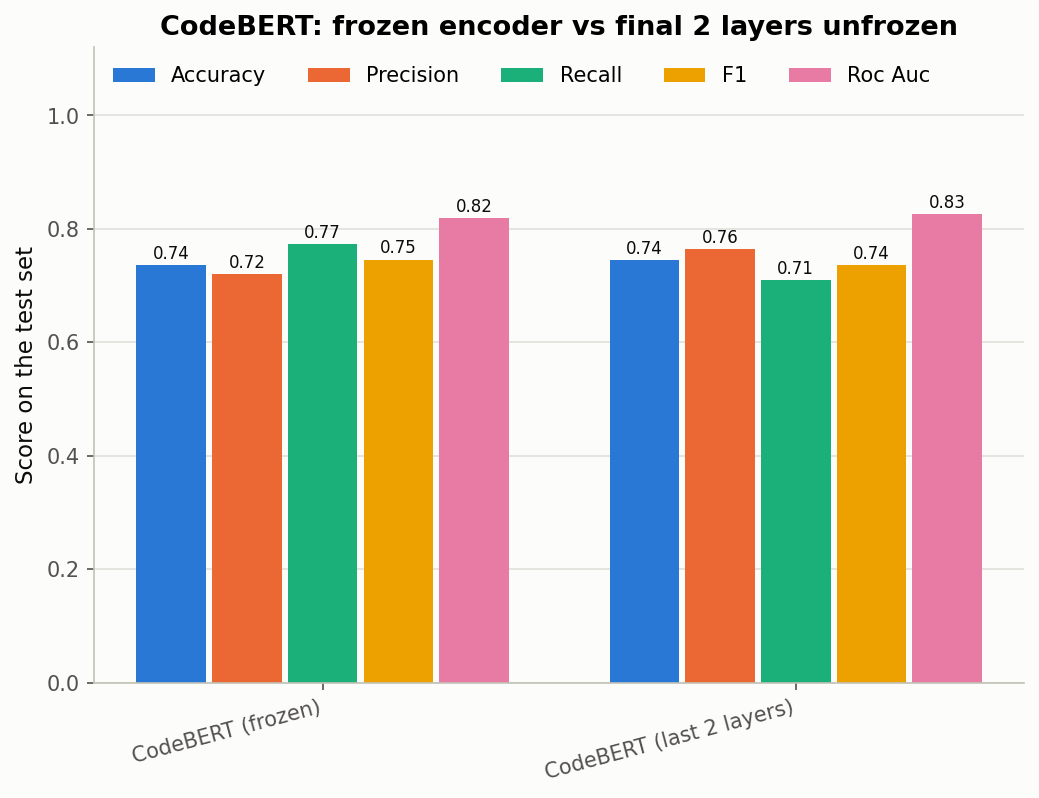

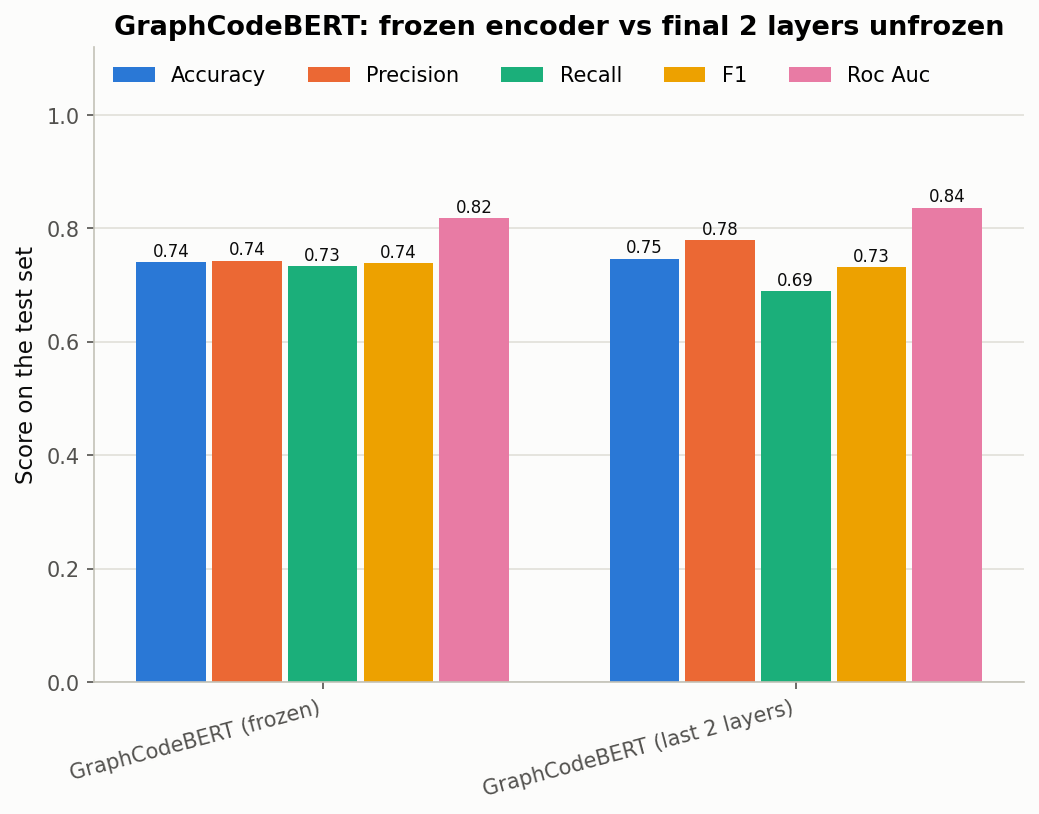

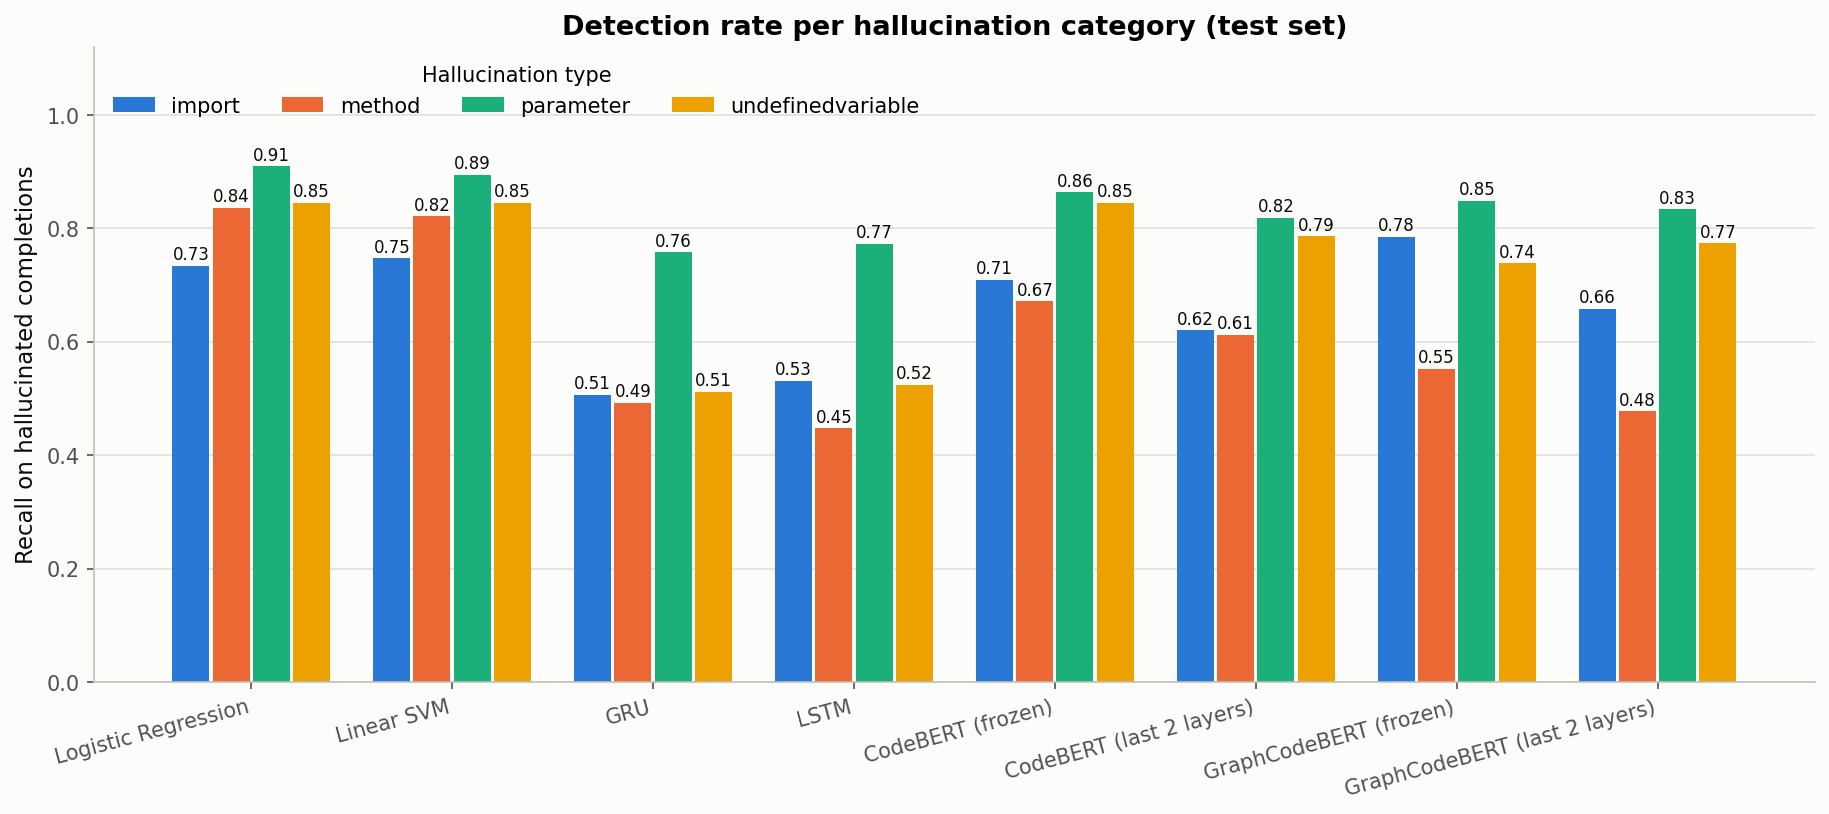

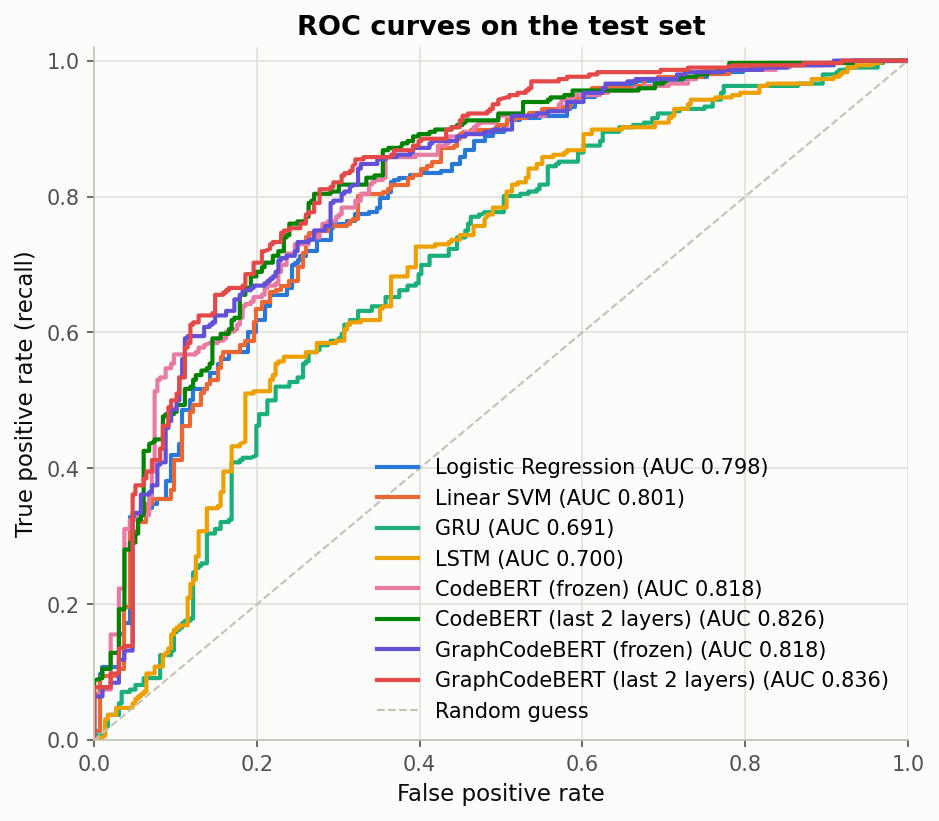

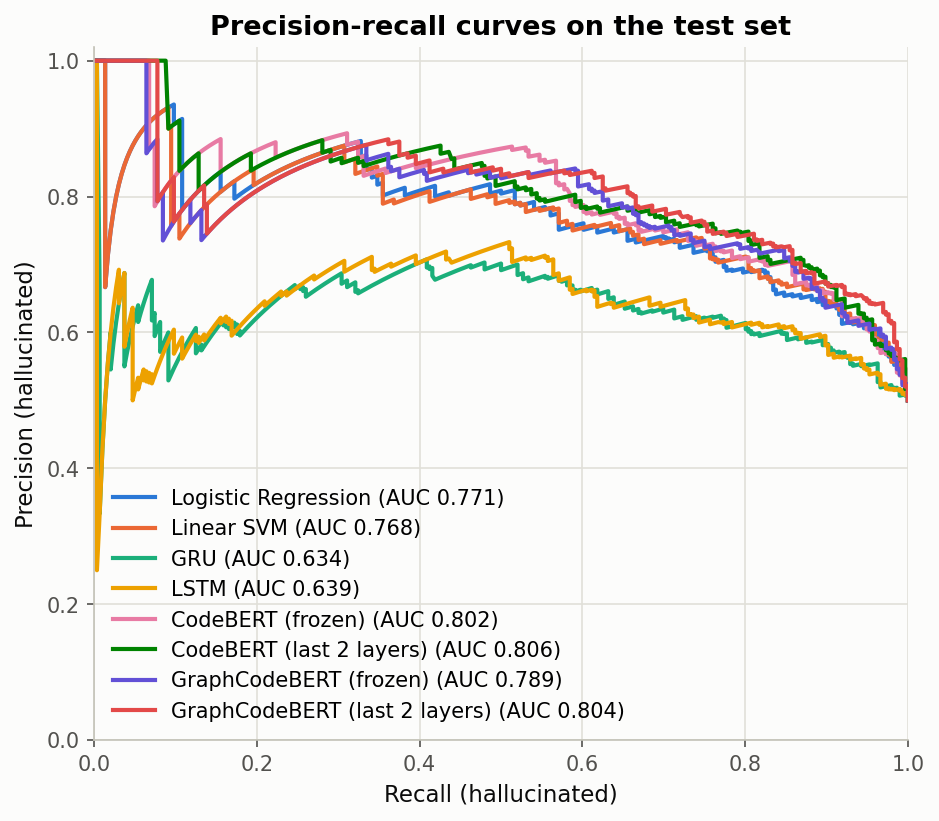

In [19]:
import os
from IPython.display import Image, display
figures = ['comparison_accuracy', 'comparison_precision', 'comparison_recall', 'comparison_f1',
           'comparison_all_metrics', 'frozen_vs_finetuned_codebert', 'frozen_vs_finetuned_graphcodebert',
           'comparison_recall_by_category', 'comparison_roc_curves', 'comparison_pr_curves']
for name in figures:
    path = f'outputs/figures/{name}.png'
    if os.path.exists(path):
        display(Image(path, width=750))
    else:
        print('not available yet:', path)

In [20]:
import pandas as pd
from IPython.display import Markdown, display
display(pd.read_csv('outputs/metrics/model_comparison.csv'))
display(Markdown(open('outputs/metrics/comparison_summary.md', encoding='utf-8').read()))

,model,display_name,status,accuracy,precision,recall,f1,roc_auc,pr_auc,pairwise_accuracy,f1_ci_low,f1_ci_high,n_test_examples
0,logistic_regression,Logistic Regression,completed,0.721284,0.682451,0.827703,0.748092,0.798142,0.771140,0.915541,0.723525,0.771570,592
1,linear_svm,Linear SVM,completed,0.719595,0.681564,0.824324,0.746177,0.800733,0.768255,0.922297,0.721107,0.771388,592
2,gru,GRU,completed,0.648649,0.680328,0.560811,0.614815,0.691221,0.633743,0.822635,0.575756,0.653503,592
3,lstm,LSTM,completed,0.658784,0.695833,0.564189,0.623134,0.699758,0.639276,0.839527,0.581885,0.661713,592
4,codebert_frozen,CodeBERT (frozen),completed,0.736486,0.720126,0.773649,0.745928,0.818367,0.801744,0.913851,0.714991,0.774716,592
5,codebert_finetuned_last2,CodeBERT (last 2 layers),completed,0.744932,0.763636,0.709459,0.735552,0.825854,0.806470,0.900338,0.701055,0.768960,592
6,graphcodebert_frozen,GraphCodeBERT (frozen),completed,0.739865,0.743151,0.733108,0.738095,0.817978,0.789159,0.920608,0.704875,0.768463,592
7,graphcodebert_finetuned_last2,GraphCodeBERT (last 2 layers),completed,0.746622,0.778626,0.689189,0.731183,0.835932,0.804451,0.930743,0.692005,0.764085,592


# Final comparison - answers generated from saved test predictions

Positive class = 1 = hallucinated. All models are evaluated on the same untouched test split.
Each question compares the model with the best test F1 in each group. The verdict is
'Yes' only if F1, accuracy AND ROC-AUC all improve, 'No' if none improve, otherwise 'Mixed'.

1. **Did the RNN outperform the traditional baseline?** No. Best RNN: LSTM (F1 0.6231, accuracy 0.6588, ROC-AUC 0.6998) vs best baseline: Logistic Regression (F1 0.7481, accuracy 0.7213, ROC-AUC 0.7981). Differences: F1 -0.1250, accuracy -0.0625, ROC-AUC -0.0984. The 95% bootstrap F1 intervals do not overlap.
2. **Did the pretrained model outperform the RNN?** Yes. Best pretrained model: CodeBERT (frozen) (F1 0.7459, accuracy 0.7365, ROC-AUC 0.8184) vs best RNN: LSTM (F1 0.6231, accuracy 0.6588, ROC-AUC 0.6998). Differences: F1 +0.1228, accuracy +0.0777, ROC-AUC +0.1186. The 95% bootstrap F1 intervals do not overlap.
3. **Did unfreezing the final two layers improve over the frozen encoder?**
   - codebert: Mixed (the metrics disagree). Best last-2-layers codebert: CodeBERT (last 2 layers) (F1 0.7356, accuracy 0.7449, ROC-AUC 0.8259) vs best frozen codebert: CodeBERT (frozen) (F1 0.7459, accuracy 0.7365, ROC-AUC 0.8184). Differences: F1 -0.0104, accuracy +0.0084, ROC-AUC +0.0075. The 95% bootstrap F1 intervals overlap, so the difference may not be reliable.
   - graphcodebert: Mixed (the metrics disagree). Best last-2-layers graphcodebert: GraphCodeBERT (last 2 layers) (F1 0.7312, accuracy 0.7466, ROC-AUC 0.8359) vs best frozen graphcodebert: GraphCodeBERT (frozen) (F1 0.7381, accuracy 0.7399, ROC-AUC 0.8180). Differences: F1 -0.0069, accuracy +0.0068, ROC-AUC +0.0180. The 95% bootstrap F1 intervals overlap, so the difference may not be reliable.
4. **Best accuracy:** **GraphCodeBERT (last 2 layers)** (accuracy = 0.7466)
5. **Best recall for hallucinated code:** **Logistic Regression** (recall = 0.8277)
6. **Best F1-score:** **Logistic Regression** (f1 = 0.7481)

## Results table

| display_name | status | accuracy | precision | recall | f1 | roc_auc | pr_auc | pairwise_accuracy | f1_ci_low | f1_ci_high | n_test_examples |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Logistic Regression | completed | 0.7213 | 0.6825 | 0.8277 | 0.7481 | 0.7981 | 0.7711 | 0.9155 | 0.7235 | 0.7716 | 592 |
| Linear SVM | completed | 0.7196 | 0.6816 | 0.8243 | 0.7462 | 0.8007 | 0.7683 | 0.9223 | 0.7211 | 0.7714 | 592 |
| GRU | completed | 0.6486 | 0.6803 | 0.5608 | 0.6148 | 0.6912 | 0.6337 | 0.8226 | 0.5758 | 0.6535 | 592 |
| LSTM | completed | 0.6588 | 0.6958 | 0.5642 | 0.6231 | 0.6998 | 0.6393 | 0.8395 | 0.5819 | 0.6617 | 592 |
| CodeBERT (frozen) | completed | 0.7365 | 0.7201 | 0.7736 | 0.7459 | 0.8184 | 0.8017 | 0.9139 | 0.7150 | 0.7747 | 592 |
| CodeBERT (last 2 layers) | completed | 0.7449 | 0.7636 | 0.7095 | 0.7356 | 0.8259 | 0.8065 | 0.9003 | 0.7011 | 0.7690 | 592 |
| GraphCodeBERT (frozen) | completed | 0.7399 | 0.7432 | 0.7331 | 0.7381 | 0.8180 | 0.7892 | 0.9206 | 0.7049 | 0.7685 | 592 |
| GraphCodeBERT (last 2 layers) | completed | 0.7466 | 0.7786 | 0.6892 | 0.7312 | 0.8359 | 0.8045 | 0.9307 | 0.6920 | 0.7641 | 592 |

## 15. Save outputs and checkpoints
If the project is on Google Drive, everything is **already saved** in `NeuralProject/outputs/`.
If you uploaded the folder to `/content` (temporary!), download a zip before the session ends:

In [21]:
!zip -qr outputs.zip outputs -x 'outputs/features/*'
try:
    from google.colab import files
    files.download('outputs.zip')
except ImportError:
    print('outputs.zip created in', os.getcwd())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## (Optional) Smoke test
A 1-2 minute check that every phase runs, using a tiny subset and a temporary output folder
(it never touches `outputs/`).

In [ ]:
!python -u tests/smoke_test.py